# 02 - Benchmark of disentanglement strategies

All numbers are means over cross-validation folds of held-out metrics. Variants:

| variant | latent | regularisers |
|---|---|---|
| baseline | one 64-d space | MOSA as released (conditional decoders) |
| adversarial | one 64-d space | MOSA source discriminator |
| dip | one 64-d space | DIP-VAE-II on the aggregate posterior |
| supervised | blocks (source 4, tissue 12, EMT 2, free 48) | supervised heads |
| supervised_nocond | blocks | heads + source adversary, decoders do not see the source |
| hsic | blocks | heads + CKA independence (Lopez et al. 2018) |
| midas | blocks | heads + leakage discriminators (MIDAS-style) |
| full | blocks | heads + discriminators + CKA |
| full_nocond | blocks | as full, confusion-mode adversaries, decoders blind to source |
| sweep_adv*_hsic* | blocks | full_nocond with stronger source penalties (sim_c05 only) |

In [1]:
# parameters
RESULTS_DIR = "results"
SIM_DATASETS = ["sim_c00", "sim_c05", "sim_c09"]
REAL_DATASET = "proteomics_paired"

In [2]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from mosa_disentangle import plotting
from mosa_disentangle.data import read_dataset
from mosa_disentangle.training import block_columns

sns.set_context("paper")
plt.rcParams["figure.dpi"] = 110

In [3]:
tables = Path(RESULTS_DIR) / "tables"
long = pd.read_csv(tables / "metrics_long.csv")
summary = pd.read_csv(tables / "metrics_summary.csv")
variants = [v for v in ["baseline", "adversarial", "adversarial_confusion", "dip", "supervised",
                        "supervised_nocond", "hsic", "midas", "full", "full_nocond"]
            if v in set(long["variant"])]
sweep = sorted(v for v in set(long["variant"]) if v.startswith("sweep_"))
sweep_summary = summary[summary["variant"].isin(sweep)].copy()
long = long[long["variant"].isin(variants)].copy()
summary = summary[summary["variant"].isin(variants)].copy()
long["variant"] = pd.Categorical(long["variant"], variants, ordered=True)
summary["variant"] = pd.Categorical(summary["variant"], variants, ordered=True)
summary = summary.sort_values(["dataset", "variant"])
long.groupby(["dataset", "variant"], observed=True).size().unstack()

variant,baseline,adversarial,adversarial_confusion,dip,supervised,supervised_nocond,hsic,midas,full,full_nocond
dataset,,,,,,,,,,
proteomics_paired,3,3,3,3,3,3,3,3,3,3
sim_c00,3,3,3,3,3,3,3,3,3,3
sim_c05,3,3,3,3,3,3,3,3,3,3
sim_c09,3,3,3,3,3,3,3,3,3,3


## 1. Cost of disentanglement: held-out reconstruction

`nmse_mean` averages the per-view pooled NMSE (MOSA's score; 1 = predicting the mean). `impute_<view>` is the NMSE of a view predicted with that view hidden from the encoders (cross-view imputation, MOSA's main use case).

,impute_copynumber_mean,impute_crisprcas9_mean,impute_drugresponse_mean,impute_metabolomics_mean,impute_methylation_mean,impute_proteomics_mean,impute_transcriptomics_mean
variant,,,,,,,
baseline,0.794,0.353,0.238,1.031,0.357,0.216,0.348
adversarial,0.815,0.357,0.243,1.029,0.363,0.215,0.352
adversarial_confusion,0.816,0.354,0.241,1.034,0.361,0.214,0.349
dip,0.843,0.368,0.269,1.154,0.408,0.244,0.401
supervised,0.785,0.352,0.241,1.034,0.361,0.218,0.341
supervised_nocond,0.782,0.349,0.237,1.018,0.356,0.211,0.340
hsic,0.844,0.363,0.266,1.129,0.400,0.235,0.391
midas,0.803,0.357,0.243,1.039,0.369,0.219,0.340
full,0.832,0.360,0.263,1.110,0.397,0.232,0.381


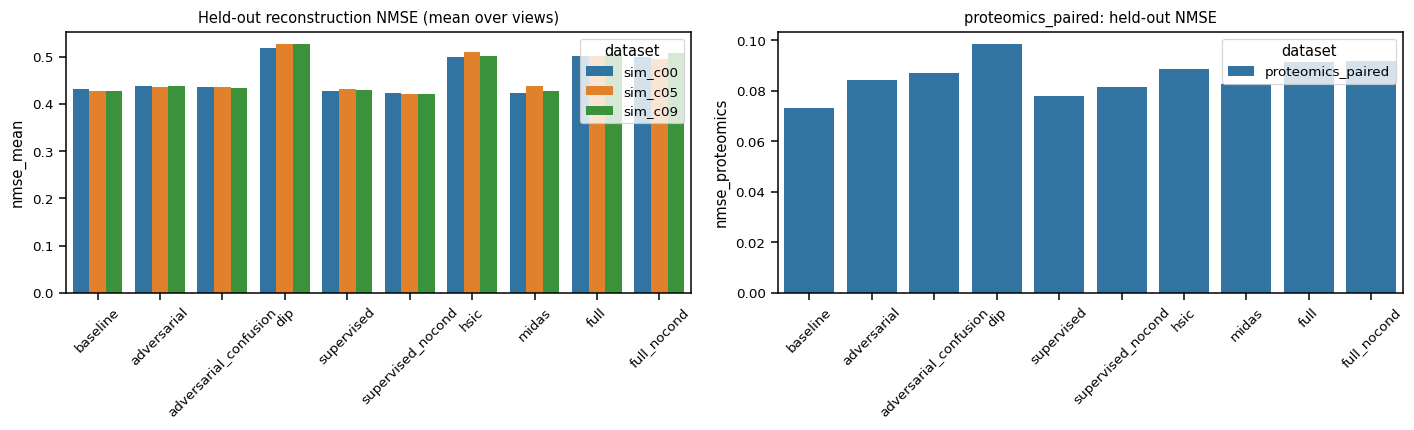

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plotting.metric_bars(summary, "nmse_mean", ax=axes[0], datasets=SIM_DATASETS,
                     title="Held-out reconstruction NMSE (mean over views)")
plotting.metric_bars(summary, "nmse_proteomics", ax=axes[1], datasets=[REAL_DATASET],
                     title=f"{REAL_DATASET}: held-out NMSE")
plt.tight_layout()
cols = [c for c in summary.columns if c.startswith("impute_") and c.endswith("_mean")]
summary[summary["dataset"] == "sim_c05"].set_index("variant")[cols].round(3)

## 2. Does each block capture its own factor and nothing else?

Probe scores are held-out balanced accuracy (categorical) or R2 (continuous) of linear probes trained on a block. `*_own` is the chance-corrected score of the factor's own block, `*_leak` the best score among the other blocks (lower is better). `probe_all_*` is the predictability from the full latent space.

In [5]:
own_leak = [c for c in summary.columns if (c.endswith("_own_mean") or c.endswith("_leak_mean"))]
view = summary[summary["dataset"].isin(SIM_DATASETS)].set_index(["dataset", "variant"])[own_leak]
view.columns = [c.replace("_mean", "") for c in view.columns]
view.round(2)

emt_leak  emt_own  model_type_leak  \
dataset variant                                                     
sim_c00 baseline                    NaN      NaN              NaN   
        adversarial                 NaN      NaN              NaN   
        adversarial_confusion       NaN      NaN              NaN   
        dip                         NaN      NaN              NaN   
        supervised                 0.79     0.85             0.85   
        supervised_nocond          0.79     0.89             0.96   
        hsic                       0.63     0.87             0.91   
        midas                      0.85     0.89             0.98   
        full                       0.65     0.87             0.86   
        full_nocond                0.63     0.87             0.89   
sim_c05 baseline                    NaN      NaN              NaN   
        adversarial                 NaN      NaN              NaN   
        adversarial_confusion       NaN      NaN              NaN   
        dip                         NaN      NaN              NaN   
        supervised                 0.79     0.88             0.86   
        supervised_nocond          0.78     0.88             0.98   
        hsic                       0.68     0.88             0.85   
        midas                      0.83     0.87             0.97   
        full                       0.68     0.87             0.88   
        full_nocond                0.74     0.89             0.89   
sim_c09 baseline                    NaN      NaN              NaN   
        adversarial                 NaN      NaN              NaN   
        adversarial_confusion       NaN      NaN              NaN   
        dip                         NaN      NaN              NaN   
        supervised                 0.73     0.88             0.99   
        supervised_nocond          0.78     0.88             0.99   
        hsic                       0.69     0.88             0.86   
        midas                      0.83     0.90             0.98   
        full                       0.62     0.86             0.81   
        full_nocond                0.69     0.85             0.87   

                               model_type_own  tissue_leak  tissue_own  
dataset variant                                                         
sim_c00 baseline                          NaN          NaN         NaN  
        adversarial                       NaN          NaN         NaN  
        adversarial_confusion             NaN          NaN         NaN  
        dip                               NaN          NaN         NaN  
        supervised                        1.0         0.36        0.53  
        supervised_nocond                 1.0         0.40        0.54  
        hsic                              1.0         0.39        0.49  
        midas                             1.0         0.43        0.55  
        full                              1.0         0.39        0.50  
        full_nocond                       1.0         0.39        0.50  
sim_c05 baseline                          NaN          NaN         NaN  
        adversarial                       NaN          NaN         NaN  
        adversarial_confusion             NaN          NaN         NaN  
        dip                               NaN          NaN         NaN  
        supervised                        1.0         0.41        0.59  
        supervised_nocond                 1.0         0.44        0.56  
        hsic                              1.0         0.45        0.56  
        midas                             1.0         0.47        0.56  
        full                              1.0         0.46        0.55  
        full_nocond                       1.0         0.45        0.56  
sim_c09 baseline                          NaN          NaN         NaN  
        adversarial                       NaN          NaN         NaN  
        adversarial_confusion             NaN          NaN         NaN

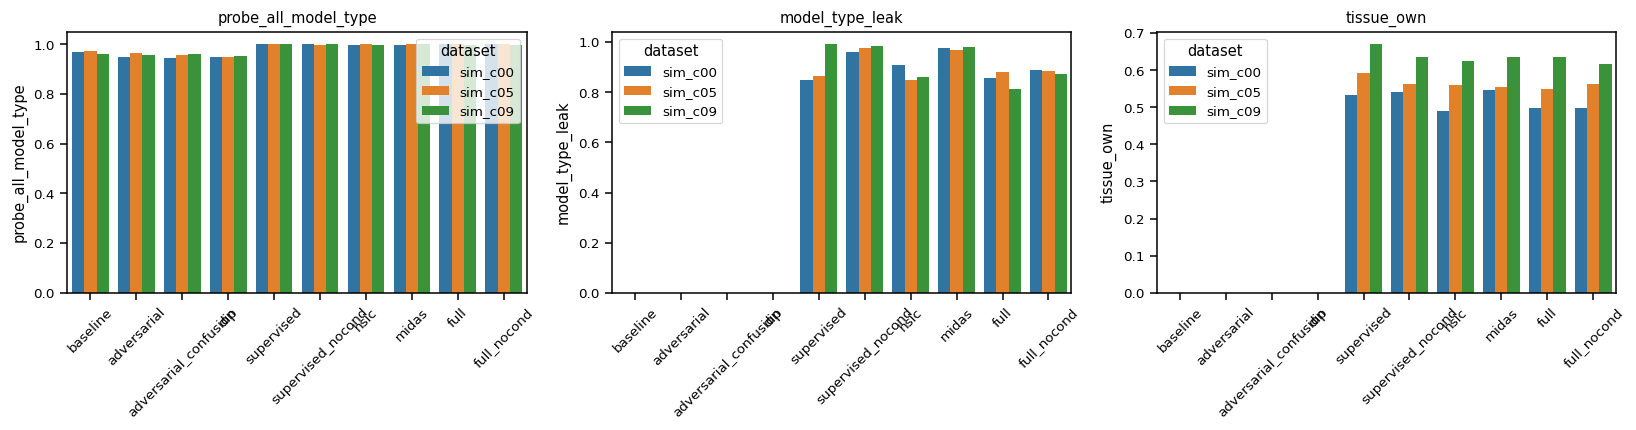

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["probe_all_model_type", "model_type_leak", "tissue_own"]):
    plotting.metric_bars(summary, metric, ax=ax, datasets=SIM_DATASETS)
plt.tight_layout()

## 3. Mixing and biological structure in the biological blocks

`source_mixing_bio`: normalised kNN entropy of the source label in the biological blocks (1 = perfectly mixed). `tissue_silhouette_bio`: silhouette of tissue labels in the same blocks (higher = clearer tissue structure).

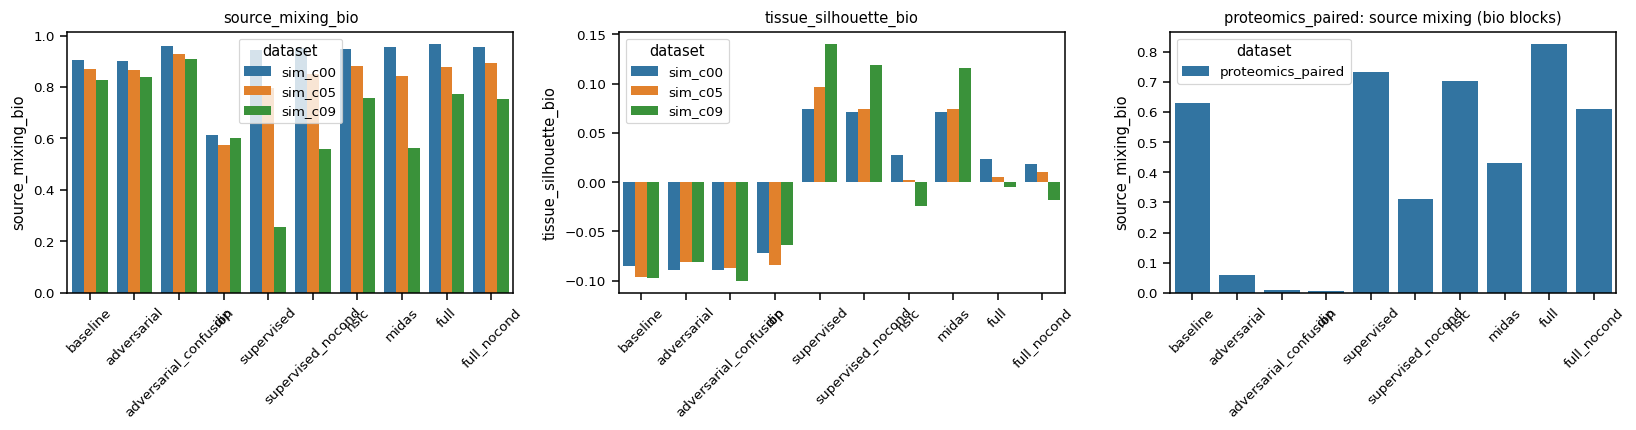

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plotting.metric_bars(summary, "source_mixing_bio", ax=axes[0], datasets=SIM_DATASETS)
plotting.metric_bars(summary, "tissue_silhouette_bio", ax=axes[1], datasets=SIM_DATASETS)
plotting.metric_bars(summary, "source_mixing_bio", ax=axes[2], datasets=[REAL_DATASET],
                     title=f"{REAL_DATASET}: source mixing (bio blocks)")
plt.tight_layout()

## 4. Counterfactual batch removal against the ground truth

Validation samples of the non-reference pseudo-sources are decoded (i) as is, (ii) with the source conditional set to the reference (MOSA's mechanism) and (iii) with the conditional swapped **and** the source block replaced by the reference prototype. Scores are NMSE against the batch-free truth; `*_missing` scores cover views that were absent in the input (counterfactual imputation).

In [8]:
cf_cols = [c for c in summary.columns if c.startswith("cf_") and c.endswith("_mean_mean")]
cf = summary[summary["dataset"].isin(SIM_DATASETS)].set_index(["dataset", "variant"])[cf_cols]
cf.columns = [c.replace("_mean_mean", "") for c in cf.columns]
cf.round(3)

cf_cond_block  cf_cond  cf_none
dataset variant                                               
sim_c00 baseline                         NaN    0.431    0.718
        adversarial                      NaN    0.429    0.712
        adversarial_confusion            NaN    0.426    0.710
        dip                              NaN    0.515    0.806
        supervised                     0.427    0.496    0.747
        supervised_nocond              0.420    0.780    0.780
        hsic                           0.499    0.527    0.840
        midas                          0.422    0.481    0.723
        full                           0.499    0.525    0.819
        full_nocond                    0.495    0.878    0.878
sim_c05 baseline                         NaN    0.428    0.712
        adversarial                      NaN    0.428    0.710
        adversarial_confusion            NaN    0.425    0.709
        dip                              NaN    0.513    0.815
        supervised                     0.434    0.491    0.760
        supervised_nocond              0.421    0.794    0.794
        hsic                           0.500    0.518    0.809
        midas                          0.441    0.500    0.770
        full                           0.492    0.512    0.806
        full_nocond                    0.491    0.866    0.866
sim_c09 baseline                         NaN    0.450    0.712
        adversarial                      NaN    0.456    0.714
        adversarial_confusion            NaN    0.447    0.701
        dip                              NaN    0.528    0.806
        supervised                     0.470    0.517    0.767
        supervised_nocond              0.446    0.754    0.754
        hsic                           0.508    0.521    0.786
        midas                          0.445    0.511    0.754
        full                           0.518    0.534    0.814
        full_nocond                    0.585    0.793    0.793

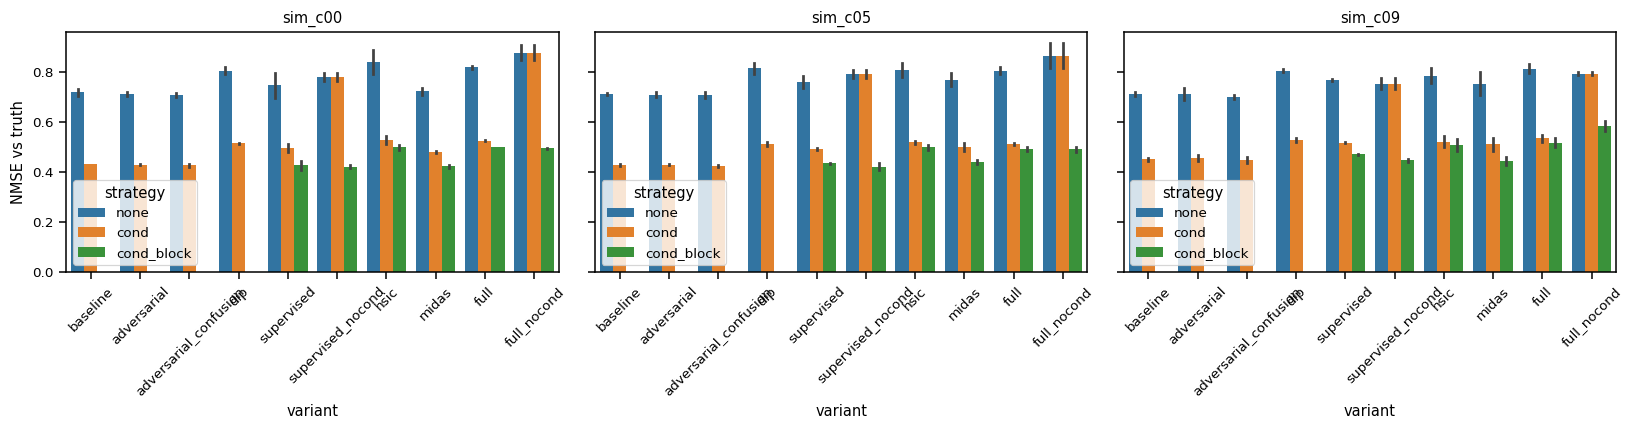

In [9]:
fig, axes = plt.subplots(1, len(SIM_DATASETS), figsize=(5 * len(SIM_DATASETS), 4), sharey=True)
for ax, ds in zip(np.atleast_1d(axes), SIM_DATASETS):
    sub = long[long["dataset"] == ds]
    melted = sub.melt(id_vars=["variant"], value_vars=[c for c in ["cf_none_mean", "cf_cond_mean", "cf_cond_block_mean"] if c in sub],
                      var_name="strategy", value_name="NMSE vs truth")
    melted["strategy"] = melted["strategy"].str.replace("cf_", "").str.replace("_mean", "")
    sns.barplot(data=melted, x="variant", y="NMSE vs truth", hue="strategy", ax=ax, errorbar="sd")
    ax.set_title(ds); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

## 4b. Real laboratories: paired cell lines

In `proteomics_paired`, 290 cell lines were measured by both Sanger and CCLE. `paired_top1_bio` is the fraction of CCLE rows whose Sanger measurement of the same line is the nearest Sanger neighbour in the biological blocks (chance ~ 1/300); `cf_cond_block_mean` is the NMSE of CCLE rows decoded as Sanger against the actual Sanger measurement (`cf_none_mean`: no correction).

In [10]:
real = summary[summary["dataset"] == REAL_DATASET].set_index("variant")
cols = [c for c in ["paired_top1_bio_mean", "paired_top5_bio_mean", "paired_mrr_bio_mean", "paired_top1_all_mean",
                    "cf_none_mean_mean", "cf_cond_mean_mean", "cf_cond_block_mean_mean", "nmse_proteomics_mean",
                    "source_mixing_bio_mean", "tissue_silhouette_bio_mean"] if c in real.columns]
real[cols].rename(columns=lambda c: c.replace("_mean_mean", "").replace("_mean", "")).round(3)

,paired_top1_bio,paired_top5_bio,paired_mrr_bio,paired_top1_all,cf_none,cf_cond,cf_cond_block,nmse_proteomics,source_mixing_bio,tissue_silhouette_bio
variant,,,,,,,,,,
baseline,0.069,0.221,0.162,0.069,8.493,0.212,NaN,0.073,0.631,-0.142
adversarial,0.021,0.120,0.084,0.021,8.618,0.259,NaN,0.084,0.060,-0.213
adversarial_confusion,0.028,0.100,0.079,0.028,8.127,0.297,NaN,0.087,0.008,-0.251
dip,0.014,0.045,0.051,0.014,8.687,0.217,NaN,0.098,0.007,-0.159
supervised,0.211,0.576,0.381,0.224,8.341,1.295,0.208,0.078,0.733,0.110
supervised_nocond,0.204,0.503,0.349,0.183,8.338,8.338,0.233,0.081,0.313,0.083
hsic,0.124,0.397,0.263,0.072,8.615,2.243,0.223,0.088,0.705,0.083
midas,0.179,0.472,0.317,0.148,8.752,1.049,0.209,0.083,0.429,0.077
full,0.152,0.448,0.298,0.059,8.965,2.816,0.224,0.091,0.825,0.071


## 5. Downstream informativeness

Mean held-out R2 of ridge models predicting the 200 most variable drug responses / CRISPR gene effects from the biological blocks.

In [11]:
down = [c for c in summary.columns if c.startswith("downstream_") and c.endswith("_mean")]
summary[summary["dataset"].isin(SIM_DATASETS)].set_index(["dataset", "variant"])[down].round(3)

downstream_crisprcas9_bio_mean  \
dataset variant                                                 
sim_c00 baseline                                        0.273   
        adversarial                                     0.265   
        adversarial_confusion                           0.260   
        dip                                             0.088   
        supervised                                      0.237   
        supervised_nocond                               0.283   
        hsic                                            0.186   
        midas                                           0.287   
        full                                            0.183   
        full_nocond                                     0.182   
sim_c05 baseline                                        0.259   
        adversarial                                     0.244   
        adversarial_confusion                           0.243   
        dip                                             0.077   
        supervised                                      0.264   
        supervised_nocond                               0.272   
        hsic                                            0.177   
        midas                                           0.267   
        full                                            0.171   
        full_nocond                                     0.183   
sim_c09 baseline                                        0.249   
        adversarial                                     0.246   
        adversarial_confusion                           0.230   
        dip                                             0.075   
        supervised                                      0.287   
        supervised_nocond                               0.279   
        hsic                                            0.171   
        midas                                           0.281   
        full                                            0.166   
        full_nocond                                     0.186   

                               downstream_crisprcas9_free_mean  \
dataset variant                                                  
sim_c00 baseline                                         0.273   
        adversarial                                      0.265   
        adversarial_confusion                            0.260   
        dip                                              0.088   
        supervised                                       0.216   
        supervised_nocond                                0.271   
        hsic                                             0.170   
        midas                                            0.276   
        full                                             0.171   
        full_nocond                                      0.167   
sim_c05 baseline                                         0.259   
        adversarial                                      0.244   
        adversarial_confusion                            0.243   
        dip                                              0.077   
        supervised                                       0.225   
        supervised_nocond                                0.260   
        hsic                                             0.170   
        midas                                            0.259   
        full                                             0.164   
        full_nocond                                      0.180   
sim_c09 baseline                                         0.249   
        adversarial                                      0.246   
        adversarial_confusion                            0.230   
        dip                                              0.075   
        supervised                                       0.230   
        supervised_nocond                                0.272   
        hsic                                             0.157   
        midas                       

## 5b. Penalty-strength sweep (sim_c05)

Source `adversarial_weight` (confusion mode) and `hsic_weight` on top of `full_nocond`: what it costs in reconstruction to push the source out of the biological blocks. `diverged` is the fraction of folds whose optimisation produced non-finite latent codes (their other metrics are missing).

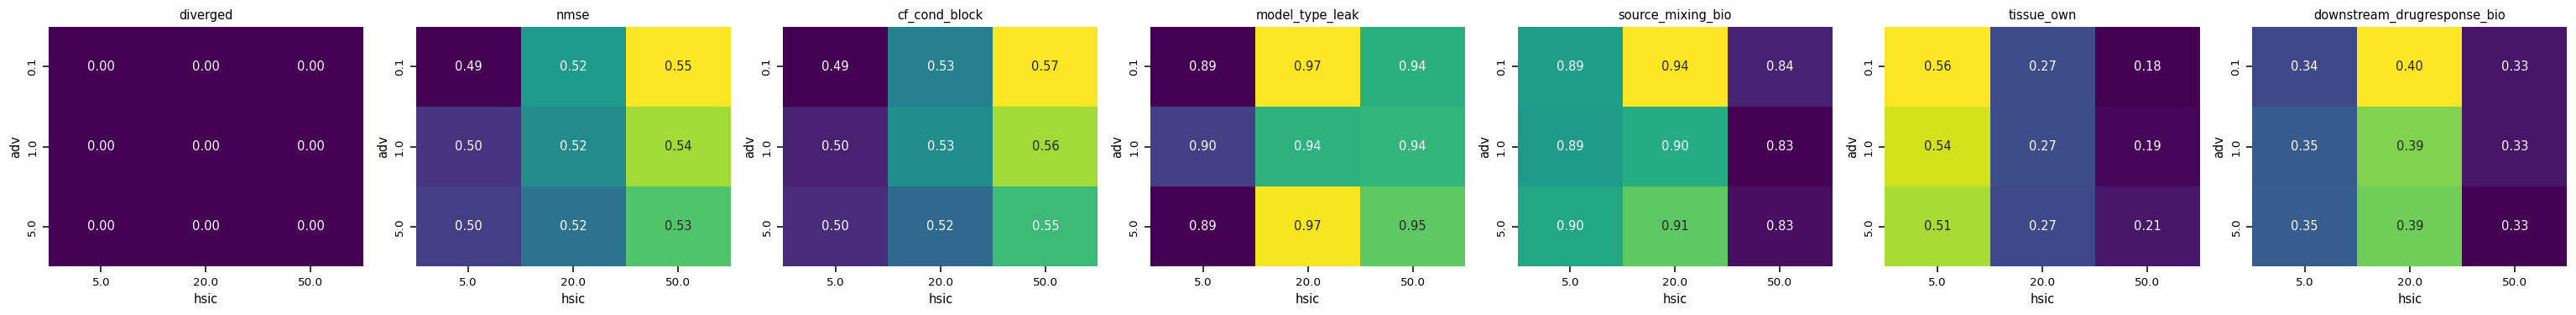

In [12]:
sw = sweep_summary[sweep_summary["dataset"] == "sim_c05"].copy()
sw["adv"] = sw["variant"].astype(str).str.extract(r"adv([0-9p]+)")[0].str.replace("p", ".").astype(float)
sw["hsic"] = sw["variant"].astype(str).str.extract(r"hsic([0-9p]+)")[0].str.replace("p", ".").astype(float)
cols = ["diverged_mean", "nmse_mean_mean", "cf_cond_block_mean_mean", "model_type_leak_mean",
        "source_mixing_bio_mean", "tissue_own_mean", "downstream_drugresponse_bio_mean"]
fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.5))
for ax, c in zip(axes, cols):
    sns.heatmap(sw.pivot(index="adv", columns="hsic", values=c), annot=True, fmt=".2f", cmap="viridis", ax=ax, cbar=False)
    ax.set_title(c.replace("_mean_mean", "").replace("_mean", ""))
plt.tight_layout()

## 6. Summary table

One row per variant on the moderately confounded simulation, ordered by the counterfactual score.

In [13]:
keys = ["nmse_mean_mean", "cf_cond_block_mean_mean", "cf_cond_mean_mean", "model_type_leak_mean",
        "tissue_own_mean", "emt_own_mean", "source_mixing_bio_mean", "tissue_silhouette_bio_mean",
        "downstream_drugresponse_bio_mean", "fit_seconds_mean"]
keys = [k for k in keys if k in summary.columns]
best = summary[summary["dataset"] == "sim_c05"].set_index("variant")[keys]
best.columns = [c.replace("_mean_mean", "").replace("_mean", "") for c in best.columns]
best.round(3)

,nmse,cf_cond_block,cf_cond,model_type_leak,tissue_own,emt_own,source_mixing_bio,tissue_silhouette_bio,downstream_drugresponse_bio,fit_seconds
variant,,,,,,,,,,
baseline,0.427,NaN,0.428,NaN,NaN,NaN,0.870,-0.096,0.478,47.330
adversarial,0.435,NaN,0.428,NaN,NaN,NaN,0.867,-0.081,0.469,54.980
adversarial_confusion,0.435,NaN,0.425,NaN,NaN,NaN,0.930,-0.087,0.455,55.511
dip,0.527,NaN,0.513,NaN,NaN,NaN,0.572,-0.084,0.253,48.142
supervised,0.431,0.434,0.491,0.864,0.593,0.883,0.796,0.097,0.490,52.200
supervised_nocond,0.421,0.421,0.794,0.976,0.563,0.882,0.850,0.074,0.505,52.383
hsic,0.509,0.500,0.518,0.850,0.561,0.879,0.881,0.002,0.334,81.065
midas,0.438,0.441,0.500,0.967,0.556,0.871,0.844,0.074,0.493,64.872
full,0.501,0.492,0.512,0.879,0.550,0.867,0.879,0.005,0.332,83.805
